## Penalized Regression: Ridge and LASSO

So far we have approached feature selection---that is, selection of which ${\bf X}$ variables to based our predictions on---by considering several subsets of features and comparing scores. But what if we want to consider *all* of the features? We don't necessarily want to select all the features to include in our model, because we run the risk of overfitting to the training data. But maybe we want to *consider* every feature for selection rather than just a few subsets. Penalized regression is one way of performing de facto feature selection: throw all the available features into the model and let the model fitting sort out which to include.

In [1]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score

We'll use the Ames housing data. We'll do a little cleaning first to:

- Drop a few columns that have mostly missing values
- Drop a few rows with missing values
- Drop the ID columns (row order and PID)

In [2]:
ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")

# Get rid of columns with mostly NaN values
good_cols = ames.isna().sum() < 100
ames = ames.loc[:,good_cols]

# Drop other NAs
ames = ames.dropna()

# drop ID columns and put target in y
X = ames.drop(["SalePrice", "Order", "PID"], axis = 1)
y = ames["SalePrice"]

X

,MS SubClass,MS Zoning,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,20,RL,31770,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,62,0,0,0,0,0,5,2010,WD,Normal
1,20,RH,11622,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,0,0,0,120,0,0,6,2010,WD,Normal
2,20,RL,14267,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,36,0,0,0,0,12500,6,2010,WD,Normal
3,20,RL,11160,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,...,0,0,0,0,0,0,4,2010,WD,Normal
4,60,RL,13830,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,...,34,0,0,0,0,0,3,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,80,RL,7937,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,...,0,0,0,0,0,0,3,2006,WD,Normal
2926,20,RL,8885,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,...,0,0,0,0,0,0,6,2006,WD,Normal
2927,85,RL,10441,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,...,32,0,0,0,0,700,7,2006,WD,Normal
2928,20,RL,10010,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,...,38,0,0,0,0,0,4,2006,WD,Normal


In [3]:
y

0       215000
1       105000
2       172000
3       244000
4       189900
         ...  
2925    142500
2926    131000
2927    132000
2928    170000
2929    188000
Name: SalePrice, Length: 2821, dtype: int64

Let's try a linear regression model first. We'll standardize numerical predictors and dummify categorical predictors.

In [4]:
ct = ColumnTransformer(
  [
    ("dummify",
    OneHotEncoder(sparse_output = False, handle_unknown='ignore'),
    make_column_selector(dtype_include=object)),
    ("standardize",
    StandardScaler(),
    make_column_selector(dtype_include=np.number))
  ],
  remainder = "passthrough"
).set_output(transform="pandas")

In [5]:
lr_pipeline = Pipeline(
  [("preprocessing", ct),
  ("linear_regression", LinearRegression())]
)

In [6]:
lr_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pa

Now let's use cross-validation to evaluate based on $R^2$.

In [7]:
cross_val_score(lr_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88433686, 0.90316706, 0.87507511, 0.91216037, 0.82269502, 0.73890838,
       0.86879893, 0.63798647, 0.90277443, 0.90350125])

Hmmm... linear regression on all the predictors does not seem as bad as the textbook suggests, though there is considerably variability between the scores based on the different folds.

Let's add second degree polynomial terms for all numerical predictors and see what happens.

In [8]:
numeric_poly = Pipeline([
    ("polynomial_features", PolynomialFeatures(degree=2)),
    ("standardize", StandardScaler())
])

ct_poly = ColumnTransformer(
    [
        ("dummify",
         OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
         make_column_selector(dtype_include=object)),

        ("numeric_poly",
         numeric_poly,
         make_column_selector(dtype_include=np.number))
    ],
    remainder="drop"
).set_output(transform="pandas")

In [9]:
poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("linear_regression", LinearRegression())]
)

In [10]:
poly_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically p

In [11]:
cross_val_score(poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([ 0.88322049, -0.2351045 , -5.18937935,  0.53298354, -1.81034894,
        0.65934136,  0.23955858, -1.0532801 , -3.71975499,  0.31162845])

OK, now that's bad. The moral is that just throwing in all the predictors might fit the training data well but can be pretty terrible when it comes to making predictions for new observations. We want to be more selective without having to laboriously search through many possible subsets of predictors. With 67 predictors there are $2^{67}\approx 10^{20}$ possible subsets---even before we consider polynomial terms, interactions, transformations, etc---so it would be impossible to fit every possible subset.

Instead, we include all predictors but "penalize" variables that don't contribute much to the model. Before getting to the penalty we'll consider some motivating conceptual questions.

1. Consider a simple linear regression of sale price on a single variable like living area. What is the process by which the coefficient for living area is determined? How does "least squares" work? **DISCUSS**

In linear regression, the coefficient for living area is determined by finding the line that best fits the data. Least squares works by calculating the differences between the actual sale prices and the predicted prices, squaring those differences, and finding the line that makes the total squared error as small as possible. The coefficient tells us how much the predicted sale price changes when living area increases by one unit.

2. Now consider a multiple of regression on living area and number of bedrooms, without standardizing variables. How does least squares work in this case? **DISCUSS**

Least squares works the same way as simple linear regression, but now it uses both living area and number of bedrooms to predict sale price. It finds the coefficients for both variables that minimize the total squared differences between actual and predicted prices. The variables are kept in their original units.

3. If you fit the linear model, without standarizing variables, how do you interpret the coefficients for living area and number of bedrooms? What is their rough order of magnitude? Can we determine directly from the coefficients which variable the predicted prices are more sensitive to? **DISCUSS**

The living area coefficient tells us how much the predicted price changes for each additional square foot, holding bedrooms constant. The bedroom coefficient tells us how much the predicted price changes for one additional bedroom, holding living area constant. The living area coefficient would typically be in the hundreds of dollars, while the bedroom coefficient could be in the thousands. We cannot directly compare the coefficients because the variables use different units.

4. If you standardize the variables first, how would you interpret the model coefficients? How could you determine, roughly, which variable the predicted prices are more sensitive to? **DISCUSS**

When we standardize the variables, they are put on the same scale. Each coefficient tells us how much the predicted sale price changes when that variable increases by one standard deviation, holding the other variable constant. We can compare the absolute values of the coefficients to see which variable the predicted prices are more sensitive to. The variable with the larger absolute coefficient has a stronger effect on the predicted price for a one-standard-deviation change.

5. If we want to make the predictions *less* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

We should make the coefficient smaller by moving it closer to zero. This reduces the variable's effect on the predicted value.

6. If we want to make the predictions *not at all* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

We should make the coefficient smaller by moving it closer to zero. This reduces the variable's effect on the predicted value.

7. Why does including a penalty like in ridge regression or LASSO "shrink" coefficients towards 0? **DISCUSS**

Ridge and LASSO add a penalty for large coefficients. To reduce the penalty, the model makes the coefficients smaller and moves them closer to zero. This helps prevent overfitting and can improve predictions on new data.

8. Why is it important to standarize variables when using a penalty? **DISCUSS**

Standardizing puts all variables on the same scale so the penalty treats them fairly. Without standardizing, variables with different units could be penalized differently just because of their scale.

9. What happens if the penalty parameter $\lambda$ is 0? **DISCUSS**

When λ = 0, there is no penalty on the coefficients. The model becomes ordinary least squares regression because it only tries to minimize the squared errors without shrinking the coefficients.

10. What happens as the penalty parameter $\lambda$ gets larger and larger? **DISCUSS**

As λ gets larger, the penalty becomes stronger and the coefficients get smaller. In Ridge regression, they move closer to zero, while in LASSO, some coefficients can become exactly zero. If λ is too large, the model may underfit the data.

11. Why do we not penalize the intercept? **DISCUSS**

We don't penalize the intercept because it represents the baseline prediction. Penalizing it would shift the predictions unnecessarily and could make the model less accurate. We only want to shrink the coefficients of the predictor variables.

12. Assume $\lambda = 1$. Suppose a standardized predictor has a small coefficient, say $\beta = 0.1$. How much does that coefficient add to the LASSO penalty versus the ridge penalty? If the coefficient were reduced from 0.1 to 0, how much would each penalty decrease? Which penalty offers a larger payoff for eliminating a small coefficient entirely? **DISCUSS**

With λ = 1 and β = 0.1, the LASSO penalty is 1 × |0.1| = 0.1, while the Ridge penalty is 1 × (0.1)² = 0.01.

If we reduce the coefficient to zero, the LASSO penalty decreases by 0.1, while the Ridge penalty decreases by 0.01.

LASSO offers a larger payoff for eliminating small coefficients, which is why it can remove variables completely from the model.

- Ridge regression shrinks all coefficient estimates toward zero but typically keeps every predictor in the model.
- LASSO regression shrinks coefficients and can set some exactly to zero, automatically removing those predictors.
- Choose ridge when predictors are highly correlated and you think many of them contain useful predictive information. Ridge tends to share influence among correlated variables.
- Choose LASSO when you want a simpler, more interpretable model with automatic variable selection.
- With highly correlated predictors, LASSO may keep one and drop the others—sometimes somewhat arbitrarily—while ridge usually retains all of them with smaller coefficients.
- Both methods are useful when there are many predictors or when ordinary least squares may overfit.

**Note that in scikit-learn the penalty parameter $\lambda$ is called `alpha`.**

## Ridge Regression

Let's fit regression regression first.

In [12]:
ridge_pipeline = Pipeline(
  [("preprocessing", ct),
  ("ridge_regression", Ridge(alpha=1))]
)

In [13]:
ridge_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('ridge_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

In [14]:
cross_val_score(ridge_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88714414, 0.90234101, 0.87838221, 0.92163172, 0.8345624 , 0.74313152,
       0.86135562, 0.68453605, 0.91776347, 0.90466508])

There are a lot of predictors so there are a lot of coefficients. The code below is just an illustration of how the coefficients in the ridge regression model compare to the original linear regression model.

In [15]:
coef_compare = pd.DataFrame()
coef_compare["feature"] = lr_pipeline.named_steps["preprocessing"].get_feature_names_out()

coef_compare["lr"] = lr_pipeline.named_steps['linear_regression'].coef_
coef_compare["ridge"] = ridge_pipeline.named_steps['ridge_regression'].coef_
coef_compare["diff"] = abs(coef_compare["lr"]) - abs(coef_compare["ridge"])

In [16]:
coef_compare.sort_values(by = "diff", ascending=False)

,feature,lr,ridge,diff
91,dummify__Roof Matl_ClyTile,-559653.342134,-233156.089658,326497.252476
93,dummify__Roof Matl_Membran,119504.966230,32582.552859,86922.413371
94,dummify__Roof Matl_Metal,109059.255835,28387.663156,80671.592679
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126
...,...,...,...,...
9,dummify__Lot Shape_IR2,3714.571039,7298.885203,-3584.314165
45,dummify__Neighborhood_NoRidge,23073.438286,27838.034970,-4764.596685
46,dummify__Neighborhood_NridgHt,17323.198503,22416.699195,-5093.500692
111,dummify__Exterior 1st_Stucco,-609.269882,-5946.929666,-5337.659785


Let's add a ridge penalty to the polynomial regression

In [17]:
ridge_poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("ridge_regression", Ridge(alpha=1))]
)

In [18]:
ridge_poly_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('ridge_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pa

In [19]:
cross_val_score(ridge_poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([ 0.91643374,  0.91589548,  0.52803531,  0.84083074,  0.78663152,
        0.68627357,  0.85705628, -0.04182712,  0.419092  ,  0.83885314])

In [20]:
poly_coef_compare = pd.DataFrame()

poly_coef_compare["feature"] = poly_pipeline.named_steps["preprocessing"].get_feature_names_out()

poly_coef_compare["lr_poly"] = poly_pipeline.named_steps["linear_regression"].coef_
poly_coef_compare["ridge_poly"] = ridge_poly_pipeline.named_steps["ridge_regression"].coef_

poly_coef_compare["diff_poly"] = (
    poly_coef_compare["lr_poly"].abs()
    - poly_coef_compare["ridge_poly"].abs()
)

In [21]:
poly_coef_compare.sort_values(by = "diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly
794,numeric_poly__Garage Cars Yr Sold,3.387006e+06,-4620.485750,3.382386e+06
244,numeric_poly__Garage Cars,-3.245972e+06,-5390.912549,3.240581e+06
834,numeric_poly__3Ssn Porch Yr Sold,-3.033907e+06,2595.063963,3.031312e+06
804,numeric_poly__Garage Area Yr Sold,-2.974090e+06,-4376.452692,2.969713e+06
245,numeric_poly__Garage Area,2.798078e+06,-4469.165800,2.793609e+06
...,...,...,...,...
51,dummify__Neighborhood_Somerst,1.597666e+03,6782.704918,-5.185039e+03
46,dummify__Neighborhood_NridgHt,3.863365e+03,9412.370927,-5.549006e+03
334,numeric_poly__Overall Qual Gr Liv Area,5.111578e+03,11990.016265,-6.878439e+03
739,numeric_poly__Bedroom AbvGr 3Ssn Porch,7.009193e+03,14597.269287,-7.588076e+03


## LASSO

Now let's try LASSO

In [22]:
lasso_pipeline = Pipeline(
  [("preprocessing", ct),
  ("lasso_regression", Lasso(alpha=1))]
)

In [23]:
lasso_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('lasso_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

In [24]:
cross_val_score(lasso_pipeline, X, y, cv = 10, scoring = 'r2')

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.029269e+09, tolerance: 1.571e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.337372e+09, tolerance: 1.603e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.271493e+

array([0.88518658, 0.90350535, 0.87598015, 0.91272267, 0.84018431, 0.74897011,
       0.87210755, 0.6385441 , 0.90335199, 0.91467053])

In [25]:
coef_compare["lasso"] = lasso_pipeline.named_steps['lasso_regression'].coef_
coef_compare["ridge_lasso_diff"] = abs(coef_compare["ridge"]) - abs(coef_compare["lasso"])

In [26]:
coef_compare.sort_values(by = "ridge_lasso_diff", ascending=False)

,feature,lr,ridge,diff,lasso,ridge_lasso_diff
126,dummify__Exterior 2nd_PreCast,37584.951869,25708.646790,11876.305079,623.765038,25084.881752
98,dummify__Roof Matl_WdShngl,118966.036255,83910.181360,35055.854896,58830.723632,25079.457727
96,dummify__Roof Matl_Tar&Grv,61103.839805,24715.717943,36388.121863,12.313931,24703.404012
95,dummify__Roof Matl_Roll,55399.766568,16828.505080,38571.261487,-987.398326,15841.106754
92,dummify__Roof Matl_CompShg,47815.565877,26802.263636,21013.302241,-11572.161484,15230.102152
...,...,...,...,...,...,...
68,dummify__Condition 2_PosN,-113384.181772,-77996.160321,35388.021451,-111624.851127,-33628.690806
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126,60878.855589,-36311.327812
109,dummify__Exterior 1st_PreCast,37584.951869,25708.646790,11876.305079,76167.305679,-50458.658888
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159,132015.733845,-65485.048008


How many ridge coefficients are 0?

In [27]:
(coef_compare["ridge"] == 0).sum()

np.int64(0)

How many LASSO coefficients are 0?

In [28]:
(coef_compare["lasso"] == 0).sum()

np.int64(24)

Let's add a lasso penalty to the polynomial regression

In [29]:
lasso_poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("lasso_regression", Lasso(alpha=1))]
)

In [30]:
lasso_poly_pipeline.fit(X, y)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.197746e+11, tolerance: 1.793e+09
  model = cd_fast.enet_coordinate_descent(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('lasso_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pa

In [31]:
cross_val_score(lasso_poly_pipeline, X, y, cv = 10, scoring = 'r2')

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.799840e+11, tolerance: 1.633e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.591473e+11, tolerance: 1.507e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.875046e+

array([ 0.90979667,  0.92702486,  0.44652545,  0.78533568,  0.77909959,
        0.82331629,  0.85113281, -0.85238606, -0.07422078,  0.86454442])

In [32]:
poly_coef_compare["lasso_poly"] = lasso_poly_pipeline.named_steps["lasso_regression"].coef_

poly_coef_compare["ridge_lasso_diff_poly"] = (
    poly_coef_compare["ridge_poly"].abs()
    - poly_coef_compare["lasso_poly"].abs()
)

In [33]:
poly_coef_compare.sort_values(by = "ridge_lasso_diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly,lasso_poly,ridge_lasso_diff_poly
126,dummify__Exterior 2nd_PreCast,46508.615317,26111.675137,20396.940181,1934.238609,24177.436528
302,numeric_poly__Lot Area Gr Liv Area,-26349.340528,-22033.486849,4315.853679,458.529117,21574.957732
330,numeric_poly__Overall Qual Total Bsmt SF,44213.087679,27183.859599,17029.228080,9036.333895,18147.525704
769,numeric_poly__TotRms AbvGrd Misc Val,48926.675238,15902.289844,33024.385394,-3821.078063,12081.211781
334,numeric_poly__Overall Qual Gr Liv Area,5111.577636,11990.016265,-6878.438630,-0.000000,11990.016265
...,...,...,...,...,...,...
94,dummify__Roof Matl_Metal,15115.740454,10325.802612,4789.937841,45438.678668,-35112.876056
100,dummify__Exterior 1st_AsphShn,-45377.934301,-13686.992691,31690.941610,-49426.340005,-35739.347314
223,numeric_poly__Overall Qual,-61342.056286,-3803.537261,57538.519024,40803.262534,-36999.725273
109,dummify__Exterior 1st_PreCast,46508.615317,26111.675137,20396.940181,95628.406450,-69516.731313


How many ridge coefficients are 0?

In [34]:
(poly_coef_compare["ridge_poly"] == 0).sum()

np.int64(4)

How many LASSO coefficients are 0?

In [35]:
(poly_coef_compare["lasso_poly"] == 0).sum()

np.int64(51)

## Grid search on `alpha` parameter

Note that useful values of `alpha` to consider depend on the scale of the $y$ variable.

In [36]:
from sklearn.model_selection import GridSearchCV

lasso_pipeline = Pipeline(
  [("preprocessing", ct),
  ("lasso_regression", Lasso(alpha = 1))]
).set_output(transform="pandas")

alphas = {'lasso_regression__alpha': np.array([10000, 1000, 100, 10, 1])}

gscv = GridSearchCV(lasso_pipeline, param_grid=alphas, cv = 10, scoring='r2')

In [37]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.029269e+09, tolerance: 1.571e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.337372e+09, tolerance: 1.603e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.271493e+

{'mean_fit_time': array([0.06047146, 0.05106242, 0.1531225 , 0.15114532, 0.5093293 ]),
 'std_fit_time': array([0.01695424, 0.00898649, 0.01659689, 0.0424334 , 0.12921575]),
 'mean_score_time': array([0.01693718, 0.01177433, 0.01013246, 0.01391156, 0.01327057]),
 'std_score_time': array([0.00906059, 0.00392592, 0.00298953, 0.00651537, 0.00600134]),
 'param_lasso_regression__alpha': masked_array(data=[10000, 1000, 100, 10, 1],
              mask=[False, False, False, False, False],
        fill_value=999999),
 'params': [{'lasso_regression__alpha': np.int64(10000)},
  {'lasso_regression__alpha': np.int64(1000)},
  {'lasso_regression__alpha': np.int64(100)},
  {'lasso_regression__alpha': np.int64(10)},
  {'lasso_regression__alpha': np.int64(1)}],
 'split0_test_score': array([0.77315012, 0.86355064, 0.89380717, 0.89168592, 0.88518658]),
 'split1_test_score': array([0.74147501, 0.87197583, 0.90424468, 0.90485654, 0.90350535]),
 'split2_test_score': array([0.73671146, 0.81703649, 0.88225665,

In [38]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_lasso_regression__alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,mean_test_score,std_test_score,rank_test_score
0,0.060471,0.016954,0.016937,0.009061,10000,{'lasso_regression__alpha': 10000},0.773150,0.741475,0.736711,0.792426,0.727367,0.672488,0.769420,0.649719,0.810124,0.763664,0.743654,0.047894,5
1,0.051062,0.008986,0.011774,0.003926,1000,{'lasso_regression__alpha': 1000},0.863551,0.871976,0.817036,0.914216,0.835060,0.708880,0.831613,0.660023,0.913971,0.855617,0.827194,0.078337,4
2,0.153122,0.016597,0.010132,0.002990,100,{'lasso_regression__alpha': 100},0.893807,0.904245,0.882257,0.928612,0.866778,0.750009,0.857909,0.675012,0.922320,0.907350,0.858830,0.077964,1
3,0.151145,0.042433,0.013912,0.006515,10,{'lasso_regression__alpha': 10},0.891686,0.904857,0.878866,0.917118,0.850546,0.753422,0.872547,0.646129,0.907051,0.916983,0.853920,0.083110,2
4,0.509329,0.129216,0.013271,0.006001,1,{'lasso_regression__alpha': 1},0.885187,0.903505,0.875980,0.912723,0.840184,0.748970,0.872108,0.638544,0.903352,0.914671,0.849522,0.084405,3


## Elastic Net

- Elastic net combines ridge and LASSO penalties, so it both shrinks coefficients and can set some coefficients exactly to zero.
- It is often preferred when you want variable selection but also have strongly correlated predictors.
- Unlike LASSO, elastic net tends to keep correlated predictors together rather than choosing one and discarding the others.
- It has two tuning choices: the overall penalty strength and the balance between ridge-like shrinkage and LASSO-like variable selection.
- Think of it as a middle ground: ridge keeps all predictors, LASSO selects a sparse subset, and elastic net can select groups of useful predictors while dropping clearly unhelpful ones.

In [39]:
elastic_pipeline = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet(alpha=1, l1_ratio=0.5))]
)

In [40]:
cross_val_score(elastic_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.85554118, 0.84071839, 0.85482838, 0.88754895, 0.85075165, 0.72374365,
       0.80725486, 0.66306372, 0.89132019, 0.84737846])

In [41]:
elastic_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('elastic_net', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](67,)","['MS SubClass','MS Zoning','Lot Area',...,'Yr Sold','Sale Type', 'Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,67
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed t

## Elastic Net: Grid search

In [42]:
elastic_pipeline_1 = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet())]
).set_output(transform="pandas")

param_grid = {
    "elastic_net__alpha": [1, 10, 100],
    "elastic_net__l1_ratio": np.arange(0.0, 1.2, 0.2),
}

gscv = GridSearchCV(elastic_pipeline_1, param_grid=param_grid, cv = 5, scoring='r2')

In [43]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.323250e+10, tolerance: 1.477e+09
  model = cd_fast.enet_coordinate_descent(


{'mean_fit_time': array([0.06564202, 0.06867428, 0.06035328, 0.06910949, 0.08057327, 0.42962637,
        0.03688388, 0.04204702, 0.03998394, 0.03395715, 0.04276314, 0.19691873,
        0.03362136, 0.03771324, 0.03696504, 0.03252912, 0.0436492 , 0.12819953]),
 'std_fit_time': array([0.03440147, 0.028049  , 0.02271665, 0.02652484, 0.04484237, 0.06378019,
        0.00491587, 0.00678879, 0.00414478, 0.00344938, 0.00468888, 0.07132755,
        0.00154283, 0.00442873, 0.00702308, 0.00331692, 0.00540754, 0.01473574]),
 'mean_score_time': array([0.01826196, 0.01740875, 0.01421018, 0.01305413, 0.01527896, 0.01932092,
        0.01284199, 0.0136518 , 0.01290274, 0.01453223, 0.01377311, 0.01417708,
        0.02836299, 0.01058426, 0.01420231, 0.01512465, 0.01492009, 0.01313024]),
 'std_score_time': array([0.00690584, 0.00526569, 0.00614602, 0.00273885, 0.00631273, 0.00498885,
        0.00297523, 0.00457167, 0.00251787, 0.00253634, 0.00468643, 0.00176604,
        0.03128169, 0.00449653, 0.00583775, 

In [44]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_elastic_net__alpha,param_elastic_net__l1_ratio,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.065642,0.034401,0.018262,0.006906,1,0.0,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.819310,0.873468,0.775536,0.734517,0.857821,0.812131,0.051506,8
1,0.068674,0.028049,0.017409,0.005266,1,0.2,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.830470,0.881659,0.778866,0.739074,0.866618,0.819337,0.053523,7
2,0.060353,0.022717,0.014210,0.006146,1,0.4,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.842222,0.890269,0.781719,0.743712,0.876022,0.826789,0.055902,6
3,0.069109,0.026525,0.013054,0.002739,1,0.6,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.854984,0.899709,0.784092,0.748899,0.886498,0.834836,0.058726,5
4,0.080573,0.044842,0.015279,0.006313,1,0.8,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.869985,0.910922,0.786466,0.756417,0.899221,0.844602,0.061939,4
5,0.429626,0.063780,0.019321,0.004989,1,1.0,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.897744,0.910938,0.796918,0.774262,0.905899,0.857152,0.059018,3
6,0.036884,0.004916,0.012842,0.002975,10,0.0,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.492509,0.578341,0.541158,0.505389,0.563969,0.536273,0.032954,13
7,0.042047,0.006789,0.013652,0.004572,10,0.2,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.543978,0.630330,0.587613,0.549154,0.615216,0.585258,0.034473,12
8,0.039984,0.004145,0.012903,0.002518,10,0.4,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.605470,0.690470,0.640126,0.598959,0.674490,0.641903,0.036319,11
9,0.033957,0.003449,0.014532,0.002536,10,0.6,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.679356,0.759111,0.697470,0.654039,0.742257,0.706446,0.039030,10


In [45]:
y_pred = gscv_fitted.predict(X)

In [46]:
target = pd.DataFrame()

target["actual"] = y
target["predicted"] = y_pred

target

,actual,predicted
0,215000,218388.243679
1,105000,117726.828123
2,172000,65809.498269
3,244000,274770.257070
4,189900,179516.735946
...,...,...
2925,142500,158534.160801
2926,131000,138474.266725
2927,132000,107452.537001
2928,170000,176715.713297


<Axes: xlabel='actual', ylabel='predicted'>

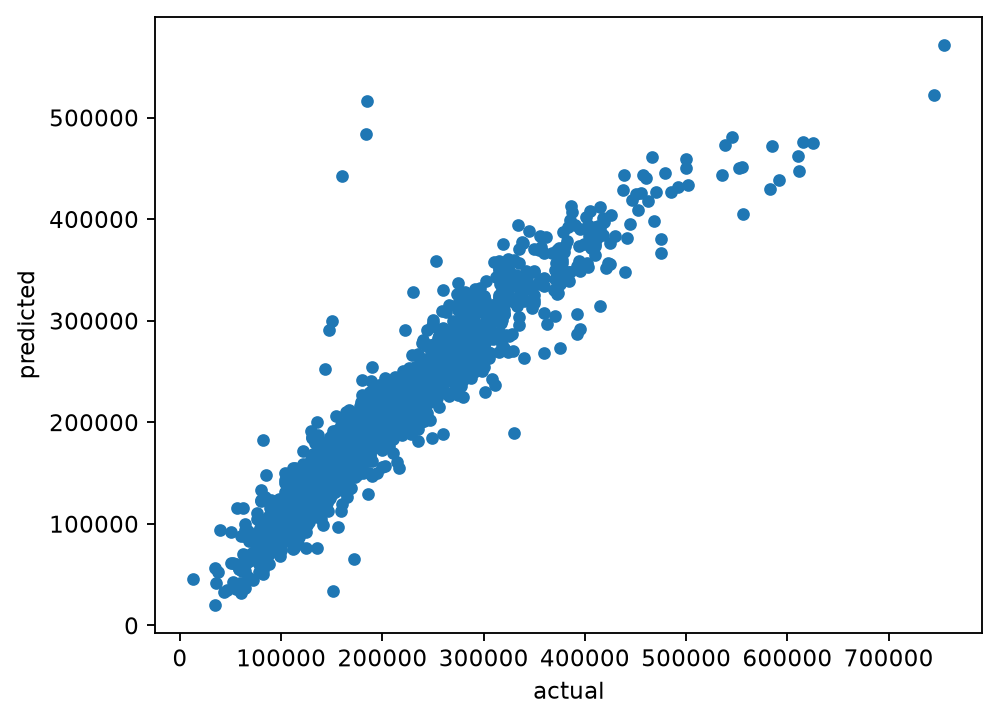

In [47]:
target.plot.scatter(x = "actual", y = "predicted")

## Practice Activity

## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

**Previously you considered selected subsets of features. Now you should try, Ridge, LASSO, and elastic net.**

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")   # hides LASSO / ElasticNet convergence warnings

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import mean_squared_error

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

In [49]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,9997,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,9998,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,9999,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0


In [50]:
df["interest_rate"].describe()

count    10000.000000
mean        12.427524
std          5.001105
min          5.310000
25%          9.430000
50%         11.980000
75%         15.050000
max         30.940000
Name: interest_rate, dtype: float64

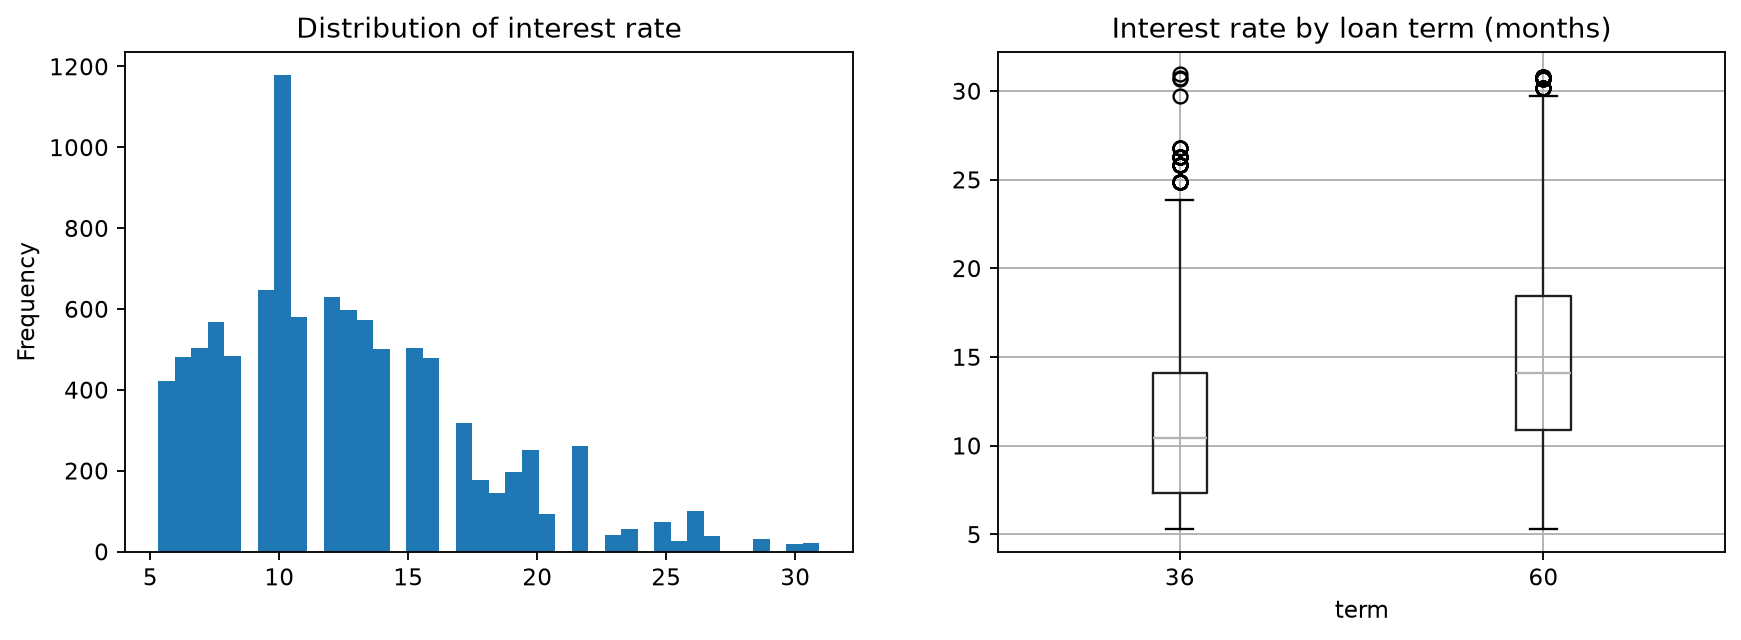

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["interest_rate"].plot.hist(bins=40, ax=ax[0], title="Distribution of interest rate")
df.boxplot(column="interest_rate", by="term", ax=ax[1])
ax[1].set_title("Interest rate by loan term (months)"); plt.suptitle("")
plt.show()

The interest rate ranges from about 5% to 31% with a mean of 12.4% and SD of 5.0. It is right-skewed. Longer (60-month) loans clearly carry higher rates, so `term` will be an important predictor.

**Benchmark:** a model that always predicts the mean has RMSE ≈ 5.0 (the SD), so any useful model needs to beat that.

### Missing values

In [52]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)

verification_income_joint           8545
annual_income_joint                 8505
debt_to_income_joint                8505
months_since_90d_late               7715
months_since_last_delinq            5658
months_since_last_credit_inquiry    1271
emp_title                            833
emp_length                           817
num_accounts_120d_past_due           318
debt_to_income                        24
dtype: int64

- The `*_joint` columns are missing for ~85% of rows because they only apply to joint applications — missing here means "not a joint application", not "unknown".
- `months_since_last_delinq` / `months_since_90d_late` are missing when the borrower has *never* been delinquent, which is informative.
- Instead of dropping rows, I'll **impute** (median for numeric, `"missing"` for categorical) and add **missing-indicator** columns so the model can learn from the missingness itself.

### Relationships with the target

In [53]:
num_corr = (df.select_dtypes(include=np.number)
              .corr()["interest_rate"]
              .drop("interest_rate")
              .sort_values(key=abs, ascending=False))
num_corr.head(15)

paid_interest                       0.514508
term                                0.358664
debt_to_income_joint                0.266417
total_debit_limit                  -0.254225
annual_income_joint                -0.165327
debt_to_income                      0.141653
num_mort_accounts                  -0.138351
inquiries_last_12m                  0.131193
total_credit_limit                 -0.130497
account_never_delinq_percent       -0.124702
accounts_opened_24m                 0.120657
earliest_credit_line                0.103635
months_since_last_credit_inquiry   -0.100945
annual_income                      -0.099584
installment                         0.098811
Name: interest_rate, dtype: float64

In [54]:
df.groupby("sub_grade")["interest_rate"].agg(["mean", "std", "count"]).head(10)

,mean,std,count
sub_grade,,,
A1,5.315545,0.004976,422
A2,6.075625,0.006029,480
A3,6.716190,0.004861,504
A4,7.345722,0.004952,568
A5,7.965649,0.004963,485
B1,9.435672,0.004958,647
B2,9.926113,0.004878,638
B3,10.416407,0.004802,540
B4,10.905267,0.004997,581


### Feature decisions (avoiding data leakage)

Some columns would make the prediction problem trivial or are only known *after* the loan is made:

| Column(s) | Why dropped |
|---|---|
| `grade`, `sub_grade` | Lending Club sets the interest rate directly from the sub-grade — within a sub-grade the SD of the rate is ≈ 0.005. Using it is essentially looking up the answer. (I show this in the appendix.) |
| `installment` | Computed from loan amount, term **and interest rate**. |
| `balance`, `paid_total`, `paid_principal`, `paid_interest`, `paid_late_fees`, `loan_status` | Happen after the loan is issued; `paid_interest` depends directly on the rate. |
| `Unnamed: 0` | Row ID. |
| `emp_title` | Free text with ~4,700 unique values — would create thousands of sparse dummies. |

I also add two engineered features: `log_annual_income` (income is very skewed) and `credit_util_ratio` = credit utilized / credit limit.

In [55]:
df["log_annual_income"] = np.log1p(df["annual_income"])
df["credit_util_ratio"] = df["total_credit_utilized"] / df["total_credit_limit"].replace(0, np.nan)

drop_cols = ["Unnamed: 0", "emp_title", "grade", "sub_grade", "installment",
             "balance", "paid_total", "paid_principal", "paid_interest",
             "paid_late_fees", "loan_status"]

X = df.drop(columns=drop_cols + ["interest_rate"])
y = df["interest_rate"]
print(X.shape)

(10000, 46)


## 2. Train / test split
The test set is set aside now and only used once at the very end.

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(8000, 46) (2000, 46)


## 3. Preprocessing pipeline
Impute → one-hot encode categoricals; impute (+ missing indicators) → standardize numerics. Standardizing matters because the penalty treats all coefficients on the same scale.

In [57]:
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
    ("dummify", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("standardize", StandardScaler())
])

ct = ColumnTransformer([
    ("cat", cat_pipe, make_column_selector(dtype_include=object)),
    ("num", num_pipe, make_column_selector(dtype_include=np.number))
])

# Polynomial version: degree-2 terms (squares + interactions) for numeric predictors
num_poly_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("standardize", StandardScaler())
])

ct_poly = ColumnTransformer([
    ("cat", cat_pipe, make_column_selector(dtype_include=object)),
    ("num", num_poly_pipe, make_column_selector(dtype_include=np.number))
])

## 4. Baseline: ordinary linear regression

In [58]:
lr_pipeline = Pipeline([("preprocessing", ct), ("model", LinearRegression())])

lr_cv = -cross_val_score(lr_pipeline, X_train, y_train, cv=5,
                         scoring="neg_root_mean_squared_error")
print("CV RMSE per fold:", lr_cv.round(3))
print("Mean CV RMSE:", lr_cv.mean().round(4))

CV RMSE per fold: [3.78  3.908 3.823 3.926 3.753]
Mean CV RMSE: 3.8381


I'll store every model's mean CV RMSE in one place for comparison.

In [59]:
results = {"Linear regression": lr_cv.mean()}

## 5. Ridge regression — tune `alpha` with GridSearchCV

In [60]:
ridge_pipeline = Pipeline([("preprocessing", ct), ("model", Ridge())])

ridge_grid = {"model__alpha": [0.1, 1, 10, 30, 100, 300, 1000]}

ridge_gscv = GridSearchCV(ridge_pipeline, param_grid=ridge_grid, cv=5,
                          scoring="neg_root_mean_squared_error")
ridge_gscv.fit(X_train, y_train)

ridge_res = pd.DataFrame(ridge_gscv.cv_results_)[["param_model__alpha", "mean_test_score", "std_test_score", "rank_test_score"]]
ridge_res["mean_test_score"] *= -1
ridge_res = ridge_res.rename(columns={"mean_test_score": "CV RMSE"})
print("Best:", ridge_gscv.best_params_, "CV RMSE =", round(-ridge_gscv.best_score_, 4))
ridge_res

Best: {'model__alpha': 100} CV RMSE = 3.8227


,param_model__alpha,CV RMSE,std_test_score,rank_test_score
0,0.1,3.837933,0.068732,6
1,1.0,3.836590,0.068932,5
2,10.0,3.830522,0.068535,4
3,30.0,3.825707,0.068174,2
4,100.0,3.822710,0.068449,1
5,300.0,3.830470,0.070186,3
6,1000.0,3.878984,0.075391,7


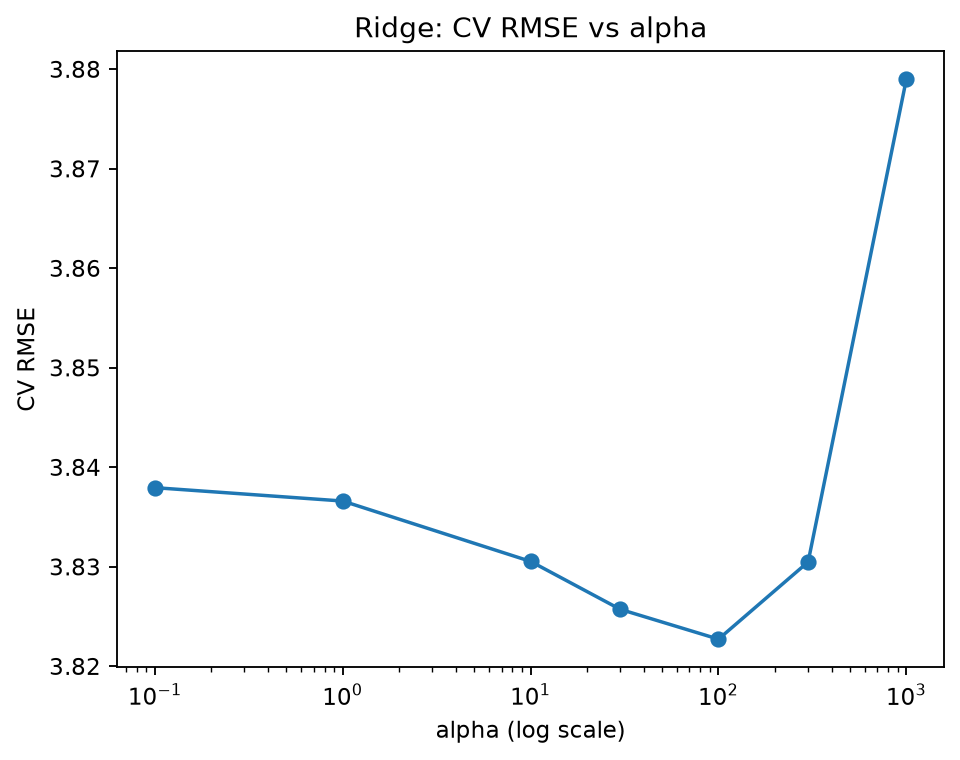

In [61]:
plt.semilogx(ridge_res["param_model__alpha"].astype(float), ridge_res["CV RMSE"], marker="o")
plt.xlabel("alpha (log scale)"); plt.ylabel("CV RMSE"); plt.title("Ridge: CV RMSE vs alpha")
plt.show()
results["Ridge"] = -ridge_gscv.best_score_

## 6. LASSO — tune `alpha` with GridSearchCV

In [62]:
lasso_pipeline = Pipeline([("preprocessing", ct), ("model", Lasso(max_iter=20000))])

lasso_grid = {"model__alpha": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}

lasso_gscv = GridSearchCV(lasso_pipeline, param_grid=lasso_grid, cv=5,
                          scoring="neg_root_mean_squared_error")
lasso_gscv.fit(X_train, y_train)

lasso_res = pd.DataFrame(lasso_gscv.cv_results_)[["param_model__alpha", "mean_test_score", "std_test_score", "rank_test_score"]]
lasso_res["mean_test_score"] *= -1
lasso_res = lasso_res.rename(columns={"mean_test_score": "CV RMSE"})
print("Best:", lasso_gscv.best_params_, "CV RMSE =", round(-lasso_gscv.best_score_, 4))
lasso_res

Best: {'model__alpha': 0.01} CV RMSE = 3.8183


,param_model__alpha,CV RMSE,std_test_score,rank_test_score
0,0.001,3.830473,0.067523,4
1,0.003,3.823129,0.065453,2
2,0.010,3.818286,0.065401,1
3,0.030,3.823733,0.062641,3
4,0.100,3.871552,0.063950,5
5,0.300,4.181542,0.088707,6


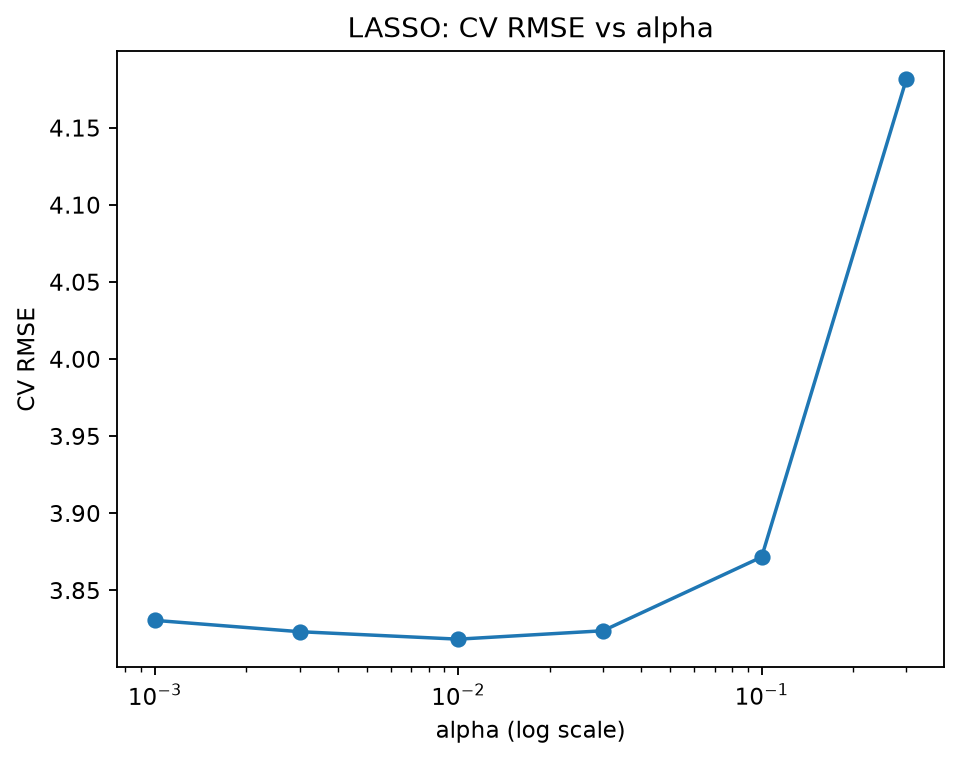

LASSO set 67 of 126 coefficients exactly to 0


In [63]:
plt.semilogx(lasso_res["param_model__alpha"].astype(float), lasso_res["CV RMSE"], marker="o")
plt.xlabel("alpha (log scale)"); plt.ylabel("CV RMSE"); plt.title("LASSO: CV RMSE vs alpha")
plt.show()

lasso_coefs = lasso_gscv.best_estimator_.named_steps["model"].coef_
print(f"LASSO set {(lasso_coefs == 0).sum()} of {len(lasso_coefs)} coefficients exactly to 0")
results["LASSO"] = -lasso_gscv.best_score_

## 7. Elastic Net — tune `alpha` and `l1_ratio` together

In [64]:
enet_pipeline = Pipeline([("preprocessing", ct), ("model", ElasticNet(max_iter=20000))])

enet_grid = {
    "model__alpha": [0.003, 0.01, 0.03, 0.1],
    "model__l1_ratio": [0.25, 0.5, 0.75, 1.0],
}

enet_gscv = GridSearchCV(enet_pipeline, param_grid=enet_grid, cv=5,
                         scoring="neg_root_mean_squared_error", n_jobs=-1)
enet_gscv.fit(X_train, y_train)

enet_res = pd.DataFrame(enet_gscv.cv_results_)
enet_table = (-enet_res.pivot(index="param_model__alpha",
                              columns="param_model__l1_ratio",
                              values="mean_test_score")).round(4)
print("Best:", enet_gscv.best_params_, "CV RMSE =", round(-enet_gscv.best_score_, 4))
print("CV RMSE (rows = alpha, columns = l1_ratio):")
enet_table

Best: {'model__alpha': 0.01, 'model__l1_ratio': 1.0} CV RMSE = 3.8183
CV RMSE (rows = alpha, columns = l1_ratio):


param_model__l1_ratio,0.25,0.50,0.75,1.00
param_model__alpha,,,,
0.003,3.8263,3.8253,3.8241,3.8231
0.010,3.8208,3.8193,3.8189,3.8183
0.030,3.8232,3.8233,3.8238,3.8237
0.100,3.8519,3.8544,3.8607,3.8716


In [65]:
results["Elastic Net"] = -enet_gscv.best_score_

The best `l1_ratio` is at or near 1, i.e. Elastic Net is choosing to behave like LASSO. All three penalized models only slightly improve on plain linear regression — with ~8,000 training rows and 126 features, OLS isn't overfitting much. To do better we need a **more flexible** model, and then the penalty becomes essential.

## 8. Adding polynomial (degree-2) terms + penalty
Degree-2 terms on the numeric predictors give 1,161 features — plain OLS would overfit badly, so the penalty has real work to do.

In [66]:
print("Number of features with polynomial terms:",
      ct_poly.fit_transform(X_train).shape[1])

Number of features with polynomial terms: 1161


In [67]:
ridge_poly_pipeline = Pipeline([("preprocessing", ct_poly), ("model", Ridge())])

ridge_poly_gscv = GridSearchCV(ridge_poly_pipeline,
                               param_grid={"model__alpha": [1000, 3000, 10000, 30000, 100000]},
                               cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_poly_gscv.fit(X_train, y_train)
print("Best:", ridge_poly_gscv.best_params_, "CV RMSE =", round(-ridge_poly_gscv.best_score_, 4))
results["Ridge + poly"] = -ridge_poly_gscv.best_score_

Best: {'model__alpha': 10000} CV RMSE = 3.9872


In [68]:
lasso_poly_pipeline = Pipeline([("preprocessing", ct_poly),
                                ("model", Lasso(max_iter=5000, tol=1e-3))])

lasso_poly_gscv = GridSearchCV(lasso_poly_pipeline,
                               param_grid={"model__alpha": [0.01, 0.02, 0.03, 0.05, 0.1]},
                               cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_poly_gscv.fit(X_train, y_train)

lp_res = pd.DataFrame(lasso_poly_gscv.cv_results_)[["param_model__alpha", "mean_test_score", "rank_test_score"]]
lp_res["mean_test_score"] *= -1
print("Best:", lasso_poly_gscv.best_params_, "CV RMSE =", round(-lasso_poly_gscv.best_score_, 4))

lp_coefs = lasso_poly_gscv.best_estimator_.named_steps["model"].coef_
print(f"LASSO kept {(lp_coefs != 0).sum()} of {len(lp_coefs)} features (set {(lp_coefs == 0).sum()} to 0)")
results["LASSO + poly"] = -lasso_poly_gscv.best_score_
lp_res.rename(columns={"mean_test_score": "CV RMSE"})

Best: {'model__alpha': 0.03} CV RMSE = 3.7508
LASSO kept 148 of 1161 features (set 1013 to 0)


,param_model__alpha,CV RMSE,rank_test_score
0,0.01,5.694283,5
1,0.02,3.806490,4
2,0.03,3.750770,1
3,0.05,3.753064,2
4,0.10,3.804824,3


Ridge with polynomial terms does *worse* than without them: it must keep all 1,161 features, so it can only shrink the noise rather than remove it. LASSO can drop the useless squared/interaction terms entirely and keep the few that matter — this is exactly the setting where LASSO's variable selection pays off.

## 9. Model comparison (cross-validated RMSE on the training set)

In [69]:
comparison = (pd.Series(results, name="Mean 5-fold CV RMSE")
                .sort_values()
                .round(4)
                .to_frame())
comparison

,Mean 5-fold CV RMSE
LASSO + poly,3.7508
LASSO,3.8183
Elastic Net,3.8183
Ridge,3.8227
Linear regression,3.8381
Ridge + poly,3.9872


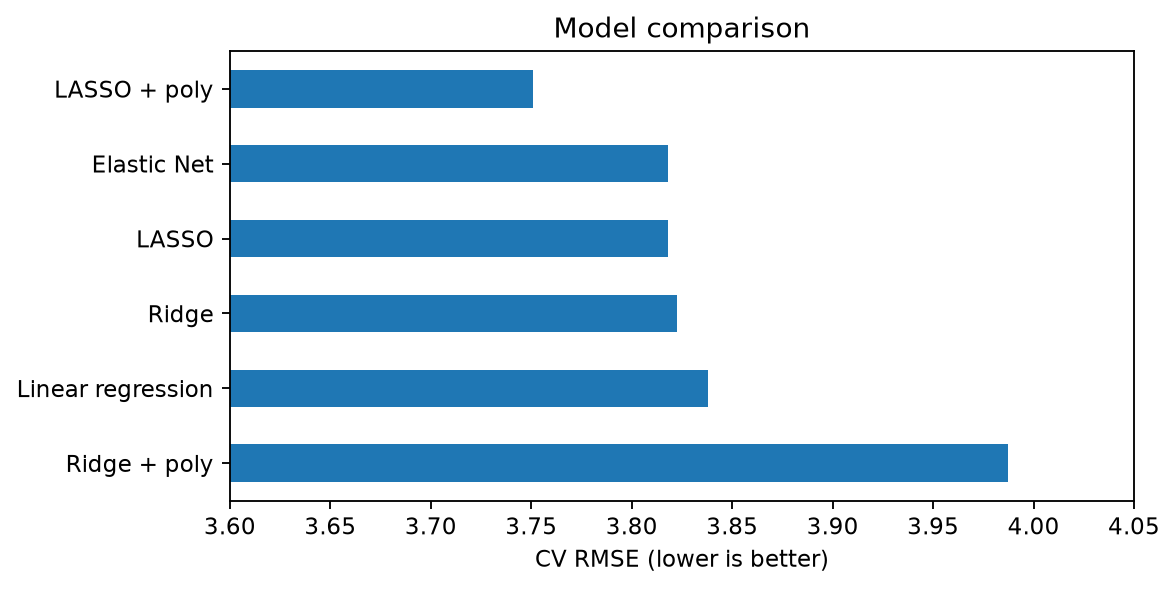

In [70]:
comparison.sort_values("Mean 5-fold CV RMSE", ascending=False).plot.barh(legend=False, figsize=(7, 3.5))
plt.xlabel("CV RMSE (lower is better)"); plt.title("Model comparison")
plt.xlim(3.6, 4.05)
plt.show()

## 10. Final model and test RMSE
The model with the lowest CV RMSE is **LASSO with degree-2 polynomial terms**. `GridSearchCV` has already refit it on the full training set with the best `alpha`; now it is evaluated **once** on the held-out test set.

In [71]:
final_model = lasso_poly_gscv.best_estimator_

y_pred_test = final_model.predict(X_test)
test_rmse = rmse(y_test, y_pred_test)

print("Final model: LASSO + degree-2 polynomial terms")
print("Best alpha:", lasso_poly_gscv.best_params_["model__alpha"])
print("CV RMSE (train):", round(-lasso_poly_gscv.best_score_, 4))
print("TEST RMSE:", round(test_rmse, 4))
print("Baseline (predict the training mean) test RMSE:",
      round(rmse(y_test, np.full(len(y_test), y_train.mean())), 4))

Final model: LASSO + degree-2 polynomial terms
Best alpha: 0.03
CV RMSE (train): 3.7508
TEST RMSE: 3.7404
Baseline (predict the training mean) test RMSE: 5.1493


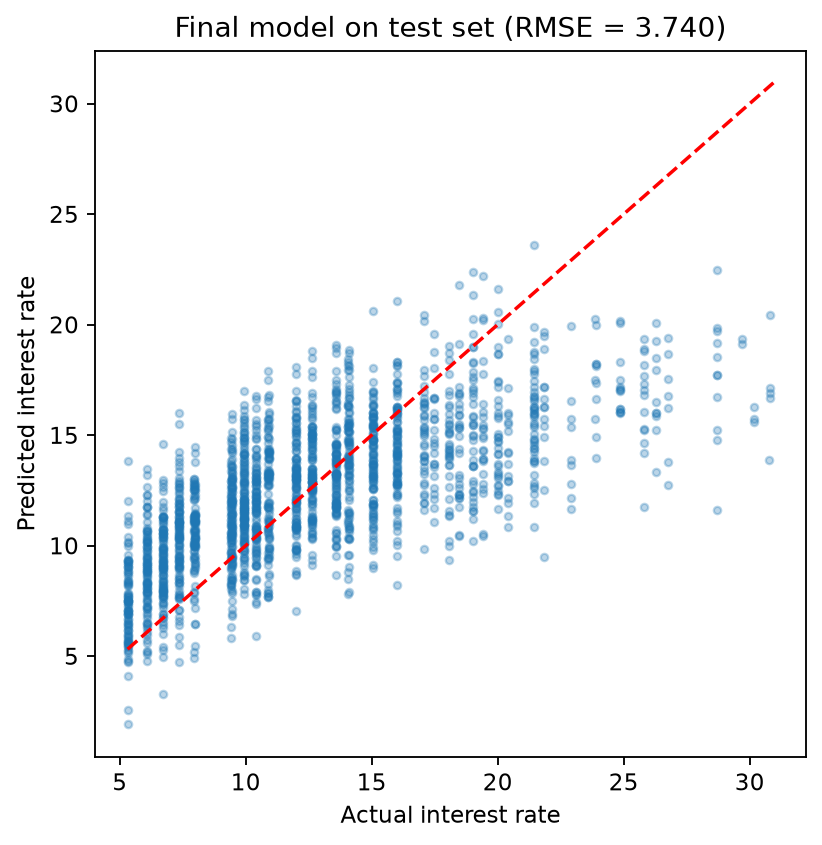

In [72]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, y_pred_test, alpha=0.3, s=10)
lims = [y.min(), y.max()]
plt.plot(lims, lims, color="red", linestyle="--")
plt.xlabel("Actual interest rate"); plt.ylabel("Predicted interest rate")
plt.title(f"Final model on test set (RMSE = {test_rmse:.3f})")
plt.show()

### Most important features in the final model

In [73]:
feature_names = final_model.named_steps["preprocessing"].get_feature_names_out()
coef_df = pd.DataFrame({"feature": feature_names, "coef": lp_coefs})
coef_df = coef_df[coef_df["coef"] != 0]
coef_df.reindex(coef_df["coef"].abs().sort_values(ascending=False).index).head(15)

,feature,coef
79,cat__disbursement_method_Cash,2.391653
77,cat__initial_listing_status_fractional,1.668016
115,num__term,1.336970
55,cat__verified_income_Verified,0.947610
252,num__debt_to_income missingindicator_annual_in...,0.914275
106,num__total_debit_limit,-0.789445
53,cat__verified_income_Not Verified,-0.607855
825,num__accounts_opened_24m term,0.567723
951,num__total_debit_limit^2,0.507034
1097,num__term credit_util_ratio,0.468182


## Appendix: what happens if `sub_grade` is included?

Just to show why it was excluded — adding `grade` and `sub_grade` back in:

In [74]:
X_sg = df.drop(columns=[c for c in drop_cols if c not in ("grade", "sub_grade")] + ["interest_rate"])
X_sg_train, X_sg_test, _, _ = train_test_split(X_sg, y, test_size=0.2, random_state=42)

sg_gscv = GridSearchCV(Pipeline([("preprocessing", ct), ("model", Lasso(max_iter=20000))]),
                       param_grid={"model__alpha": [0.0001, 0.001, 0.01]},
                       cv=5, scoring="neg_root_mean_squared_error")
sg_gscv.fit(X_sg_train, y_train)
print("Best:", sg_gscv.best_params_)
print("CV RMSE:", round(-sg_gscv.best_score_, 4))
print("Test RMSE:", round(rmse(y_test, sg_gscv.predict(X_sg_test)), 4))

Best: {'model__alpha': 0.0001}
CV RMSE: 0.1835
Test RMSE: 0.0763


To build a model for predicting interest rate, I first explored the data and removed variables that would leak the answer, such as sub_grade, installment, and the payment and balance columns. I filled in missing values and added indicator columns so the model could learn from missingness. I then held out 20% of the data as a test set and tuned Ridge, LASSO, and Elastic Net (over both alpha and l1_ratio) with 5-fold GridSearchCV, with and without degree-2 polynomial terms. On the original linear features, all three penalized models only slightly beat ordinary least squares (CV RMSE of about 3.82 versus 3.84). Elastic Net chose l1_ratio = 1, which means it behaved like LASSO. Adding polynomial terms made Ridge worse, because it has to keep every feature. It helped LASSO, though, which set 1,012 of the 1,161 expanded features to zero and kept 149. My final model is LASSO with degree-2 polynomial terms on the numeric predictors, with alpha = 0.03 chosen by cross-validation (CV RMSE = 3.751). It achieved a test RMSE of 3.740, compared with 5.149 for simply predicting the mean interest rate. Including sub_grade would drop the test RMSE below 0.1, but only because Lending Club sets the rate almost directly from sub-grade. That model wouldn’t be learning anything about borrower risk, so I did not use it as my final model.